# 02 · Cuatro décadas: de la flor industrial a la flor de altar

¿Cómo cambió la producción desde 1980? La serie larga del SIAP enseña dos épocas muy distintas: una de grandes extensiones en Sinaloa, Sonora y el Bajío, y otra, desde 2002, de pequeñas parcelas en el centro del país.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

estatal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_estatal.csv")
municipal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_municipal.csv")
FUENTE_SIAP = "Fuente: SIAP, Cierre de la Producción Agrícola 1980-2025. Análisis: Sahuaris."

In [2]:
estatal["region"] = estatal["idestado"].map(config.REGIONES).fillna(config.REGION_RESTO)
ha_region = estatal.pivot_table(index="anio", columns="region", values="sembrada", aggfunc="sum").reindex(columns=config.ORDEN_REGIONES).fillna(0)
ha_total = ha_region.sum(axis=1)
ha_region.assign(total=ha_total).round(0).astype(int)

region,Sinaloa y Sonora,"Bajío (Gto., Mich., Qro.)",Puebla,CDMX y Edomex,Resto del país,total
anio,,,,,,
1980,2714,2338,264,0,128,5444
1981,4770,2320,104,0,264,7458
1982,4920,2974,81,0,440,8415
1983,2799,1402,56,0,76,4333
1984,4899,3593,1036,0,320,9848
1985,8186,6498,2284,0,609,17577
1986,2676,607,2471,0,446,6200
1987,6359,1380,1147,0,637,9523
1988,11420,3480,2023,0,583,17506


In [3]:
pico_anio = int(ha_total.idxmax())
print(f"Pico: {pico_anio} con {ha_total.max():,.0f} ha")
print(f"2025: {ha_total.loc[2025]:,.0f} ha  ->  {ha_total.max() / ha_total.loc[2025]:.1f} veces menos que el pico")
ochentas = ha_region.loc[1980:1989]
print(f"Promedio 1980-1989: {ochentas.sum(axis=1).mean():,.0f} ha/año; Sinaloa, Sonora y Bajío = {(ochentas[config.ORDEN_REGIONES[:2]].sum().sum() / ochentas.sum().sum() * 100):.0f}%")
recientes = ha_region.loc[2021:2025]
print(f"Promedio 2021-2025: {recientes.sum(axis=1).mean():,.0f} ha/año; Sinaloa, Sonora y Bajío = {(recientes[config.ORDEN_REGIONES[:2]].sum().sum() / recientes.sum().sum() * 100):.1f}%")

Pico: 1985 con 17,577 ha
2025: 1,771 ha  ->  9.9 veces menos que el pico
Promedio 1980-1989: 9,654 ha/año; Sinaloa, Sonora y Bajío = 83%
Promedio 2021-2025: 2,227 ha/año; Sinaloa, Sonora y Bajío = 2.5%


## La superficie por región

Interactiva: outputs/figuras/02_hectareas_por_region.html


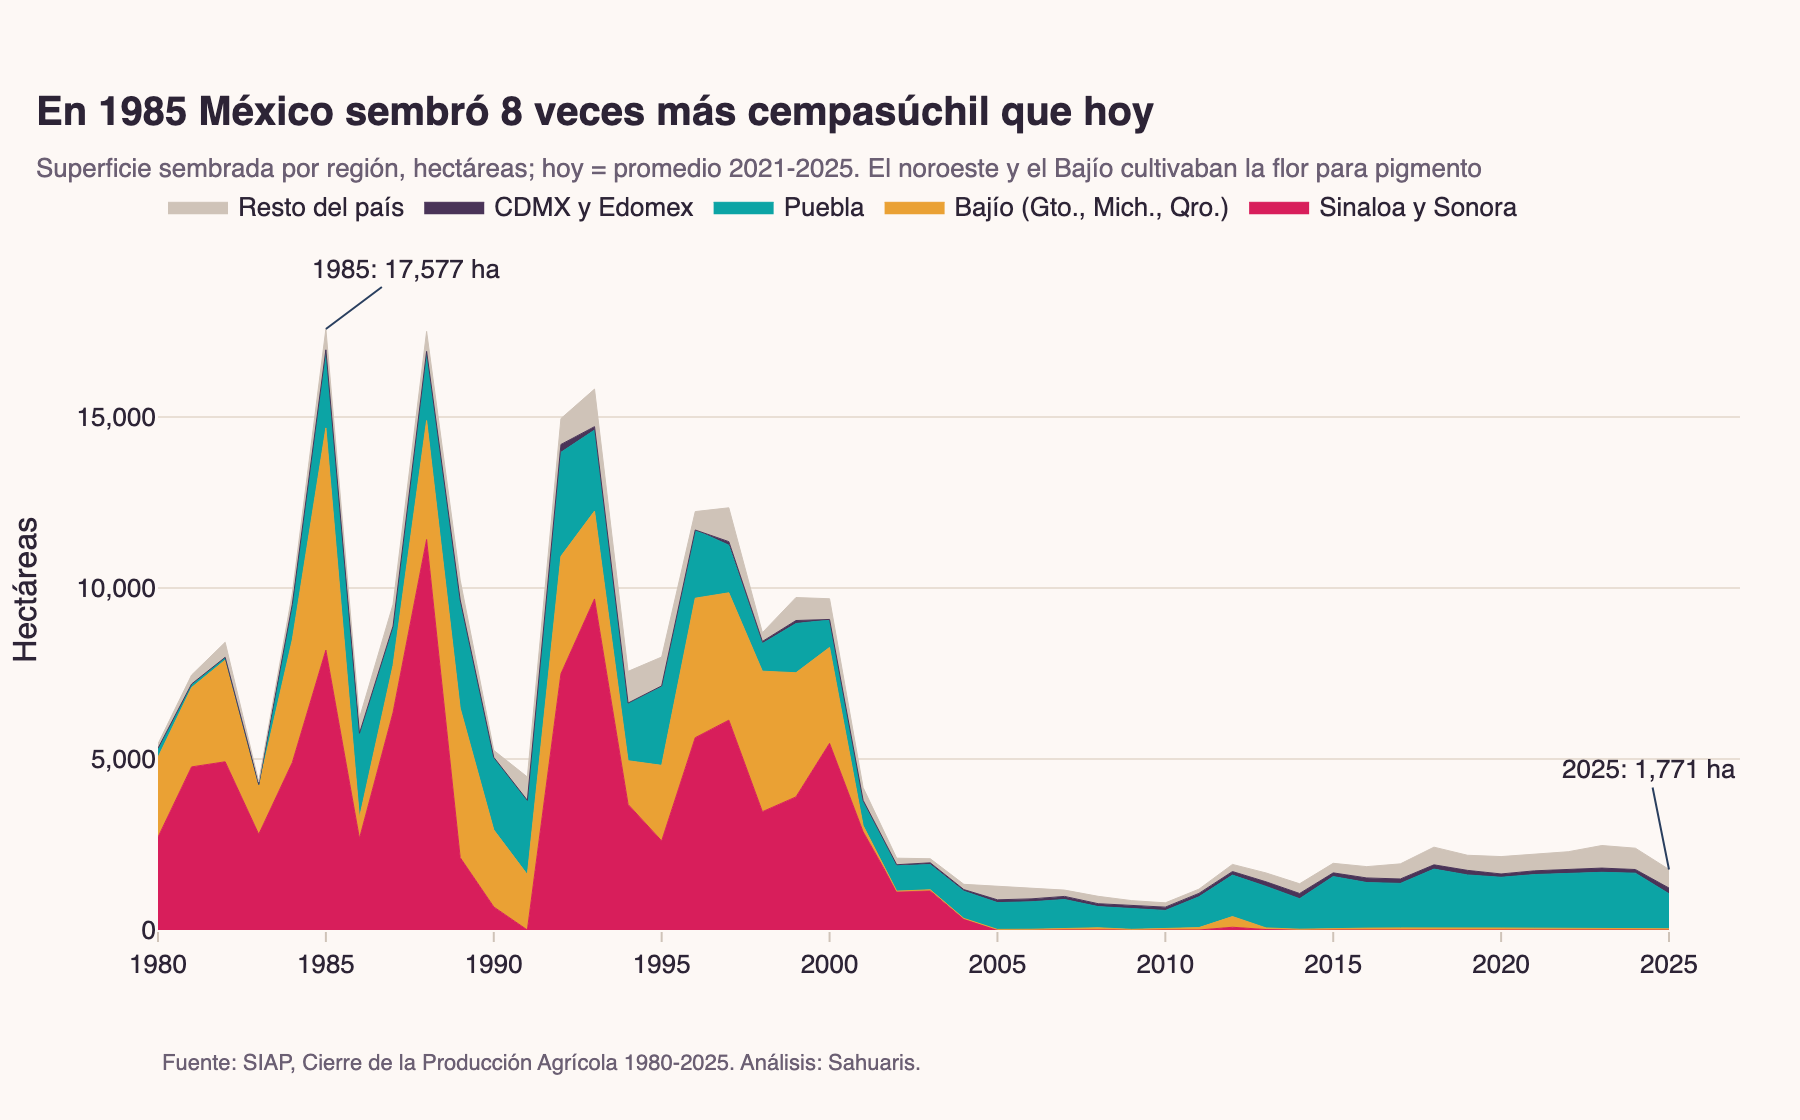

In [4]:
colores = {
    "Sinaloa y Sonora": tema.PROTAGONISTA,
    "Bajío (Gto., Mich., Qro.)": tema.TERCIARIO,
    "Puebla": tema.SECUNDARIO,
    "CDMX y Edomex": tema.CONTORNO,
    config.REGION_RESTO: tema.NEUTRO,
}
fig = go.Figure()
for region in config.ORDEN_REGIONES:
    fig.add_trace(go.Scatter(
        x=ha_region.index, y=ha_region[region], name=region, stackgroup="uno", mode="lines",
        line=dict(width=0.5, color=colores[region]), fillcolor=colores[region],
        hovertemplate=f"{region}<br>%{{x}}: %{{y:,.0f}} ha<extra></extra>",
    ))
fig.add_annotation(x=pico_anio, y=ha_total.max(), text=f"{pico_anio}: {ha_total.max():,.0f} ha", showarrow=True, arrowhead=0, ax=40, ay=-30)
fig.add_annotation(x=2025, y=ha_total.loc[2025], text=f"2025: {ha_total.loc[2025]:,.0f} ha", showarrow=True, arrowhead=0, ax=-10, ay=-50)
fig.update_layout(
    title=tema.titulo(f"En {pico_anio} México sembró {ha_total.max() / ha_total.loc[2021:2025].mean():.0f} veces más cempasúchil que hoy",
                      "Superficie sembrada por región, hectáreas; hoy = promedio 2021-2025. El noroeste y el Bajío cultivaban la flor para pigmento"),
    xaxis=dict(title=""), yaxis=dict(title="Hectáreas", tickformat=","), height=560,
)
tema.nota_fuente(fig, FUENTE_SIAP)
tema.mostrar(fig, "02_hectareas_por_region", alto=560)

## Las toneladas cuentan la misma historia

Solo la flor a granel y la forrajera se miden en toneladas, así que esta serie deja fuera las macetas y los manojos. Aun así muestra la escala de la época industrial: en 1985 se cosecharon casi 250 mil toneladas, y entre 2021 y 2025, unas 19 mil al año.

In [5]:
toneladas = estatal[estatal["nomunidad"] == "Tonelada"]
t_anual = toneladas.pivot_table(index="anio", columns="presentacion", values="volumenproduccion", aggfunc="sum").fillna(0)
t_anual["total"] = t_anual.sum(axis=1)
t_pico = int(t_anual["total"].idxmax())
t_reciente = t_anual.loc[2021:2025, "total"].mean()
print(f"Pico: {t_pico} con {t_anual.loc[t_pico, 'total']:,.0f} t; 2021-2025: {t_reciente:,.0f} t/año ({t_anual.loc[t_pico, 'total'] / t_reciente:.0f} veces menos)")
sinaloa = toneladas[toneladas["idestado"] == 25].groupby("anio")["volumenproduccion"].sum()
print(f"Sinaloa, máximo: {int(sinaloa.idxmax())} con {sinaloa.max():,.0f} t; último año con más de 100 t: {int(sinaloa[sinaloa > 100].index.max())}")

Pico: 1988 con 249,211 t; 2021-2025: 19,072 t/año (13 veces menos)
Sinaloa, máximo: 1988 con 181,151 t; último año con más de 100 t: 2012


Interactiva: outputs/figuras/02_toneladas.html


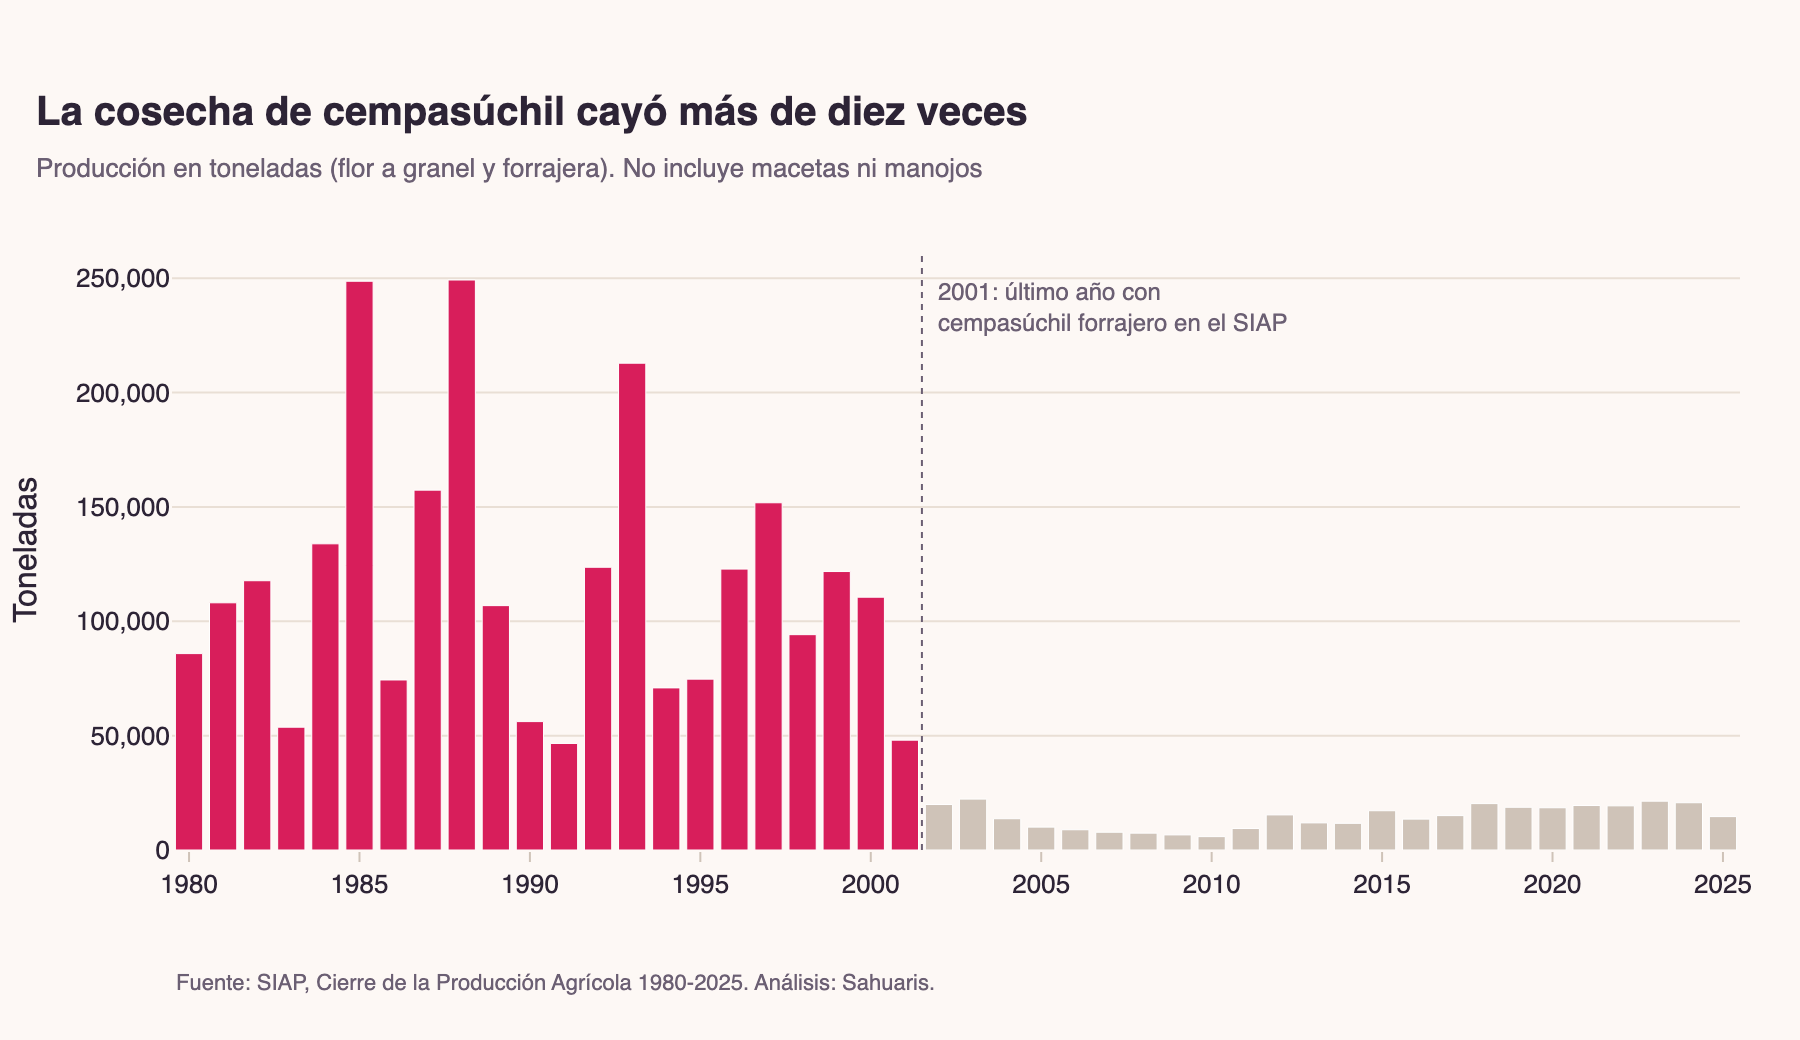

In [6]:
fig = go.Figure()
fig.add_trace(go.Bar(x=t_anual.index, y=t_anual["total"], marker_color=[tema.PROTAGONISTA if a < 2002 else tema.NEUTRO for a in t_anual.index],
                     hovertemplate="%{x}: %{y:,.0f} t<extra></extra>"))
fig.add_vline(x=2001.5, line=dict(color=tema.TEXTO_SUAVE, dash="dot", width=1))
ultimo_forrajero = int(t_anual[t_anual["Forrajero (t)"] > 0].index.max())
fig.add_annotation(x=2001.5, y=t_anual["total"].max() * 0.95, text=f"{ultimo_forrajero}: último año con<br>cempasúchil forrajero en el SIAP", showarrow=False, xanchor="left", xshift=6, align="left", font=dict(size=12, color=tema.TEXTO_SUAVE))
fig.update_layout(
    title=tema.titulo("La cosecha de cempasúchil cayó más de diez veces",
                      "Producción en toneladas (flor a granel y forrajera). No incluye macetas ni manojos"),
    xaxis=dict(title=""), yaxis=dict(title="Toneladas", tickformat=","), height=520, showlegend=False,
)
tema.nota_fuente(fig, FUENTE_SIAP)
tema.mostrar(fig, "02_toneladas", alto=520)

## Comprobación contra la prensa

Gaceta UNAM (citada por Maya Comunicación) reporta "más de 16,600 hectáreas" en 1985 con datos del SIAP. Nuestra suma da:

In [7]:
doc = pd.read_csv(config.DIR_MANUAL / "cifras_documentales.csv").set_index("id")
ha_1985 = ha_total.loc[1985]
print(f"SIAP 1985 (nuestra suma): {ha_1985:,.0f} ha  |  Gaceta UNAM: más de {doc.loc['ha_1985_gaceta', 'valor']:,} ha")
assert ha_1985 > doc.loc["ha_1985_gaceta", "valor"]
ha_region.assign(total=ha_total).to_csv(config.DIR_PROCESSED / "hectareas_por_region.csv")

SIAP 1985 (nuestra suma): 17,577 ha  |  Gaceta UNAM: más de 16,600 ha
